## Projeto 2 - CB: O que está associado aos atrasos das maiores companhias aéreas brasileiras?

**Autores:**
- Anna Albuquerque
- Mateus Cortez Camacho

---

<center>
    <img src="avião.png">
</center>
  
Os **atrasos em voos** são relevantes tanto para passageiros, que perdem conexões e compromissos, quanto para as companhias aéreas e os aeroportos, que arcam com custos operacionais e de reputação. Este trabalho investiga quais características dos voos apresentam maior relação com o atraso nas três maiores companhias aéreas do Brasil (LATAM, GOL e Azul) e se as diferenças entre elas se mantêm quando se consideram fatores como aeroporto e horário.

---

### Variáveis
- **Sigla ICAO Empresa Aérea**: Código ICAO da companhia aérea (ex.: AZU = Azul, TAM = LATAM Brasil, GLO = GOL) - *Qualitativa Nominal*
- **Empresa Aérea**: Nome da companhia aérea - *Qualitativa Nominal*
- **Número Voo**: Número do voo - *Identificação*
- **Código DI**: Código que identifica a natureza do voo (0 = voo regular) - *Qualitativa Nominal*
- **Código Tipo Linha**: Tipo de linha (N = doméstica mista, I = internacional mista, C = doméstica cargueira, G = internacional cargueira) - *Qualitativa Nominal*
- **Modelo Equipamento**: Modelo da aeronave (ex.: A320, B738) - *Qualitativa Nominal*
- **Número de Assentos**: Quantidade de assentos da aeronave - *Quantitativa Discreta*
- **Sigla ICAO Aeroporto Origem**: Código ICAO do aeroporto de partida (ex.: SBGR = Guarulhos) - *Qualitativa Nominal*
- **Descrição Aeroporto Origem**: Nome, cidade e UF do aeroporto de partida - *Qualitativa Nominal*
- **Partida Prevista**: Data e hora programadas para a partida - *Data/Hora*
- **Partida Real**: Data e hora em que a partida ocorreu - *Data/Hora*
- **Sigla ICAO Aeroporto Destino**: Código ICAO do aeroporto de chegada - *Qualitativa Nominal*
- **Descrição Aeroporto Destino**: Nome, cidade e UF do aeroporto de chegada - *Qualitativa Nominal*
- **Chegada Prevista**: Data e hora programadas para a chegada - *Data/Hora*
- **Chegada Real**: Data e hora em que a chegada ocorreu - *Data/Hora*
- **Situação Voo**: Se o voo foi realizado ou cancelado - *Qualitativa Nominal Binária*
- **Justificativa**: Motivo do atraso ou cancelamento (coluna 100% vazia nesta base) - *Qualitativa Nominal*
- **Referência**: Data de referência do voo - *Data*
- **Situação Partida**: Faixa de pontualidade da partida (Antecipado, Pontual, Atraso 30-60, 60-120, 120-240, …) - *Qualitativa Ordinal*
- **Situação Chegada**: Faixa de pontualidade da chegada (mesmas categorias) - *Qualitativa Ordinal*
- **Codeshare**: Companhia parceira e número do voo compartilhado, quando houver (vazio na maioria dos voos) - *Qualitativa Nominal*

---
## 0. Importação do dataframe

A análise utiliza a base de Voo Regular Ativo (VRA) da ANAC referente a janeiro de 2025, composta por 89.616 registros e 21 variáveis. Inicialmente, foram importadas as bibliotecas e a base de dados. As colunas de datas e horários foram convertidas para o formato de data e hora, permitindo calcular a diferença entre os horários previstos e realizados.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

df = pd.read_csv(
    "VRA_2025_01.csv",
    sep=";",
    encoding="utf-8",
    dtype={"Número Voo": str},  # mantém zeros à esquerda (ex.: "0904")
)

# no CSV as datas vêm como texto ("01/01/2025 23:55"); converter para data/hora
for col in ["Partida Prevista", "Partida Real", "Chegada Prevista", "Chegada Real", "Referência"]:
    df[col] = pd.to_datetime(df[col], dayfirst=True)

print(df.shape)
df.head()

(89616, 21)


,Sigla ICAO Empresa Aérea,Empresa Aérea,Número Voo,Código DI,Código Tipo Linha,Modelo Equipamento,Número de Assentos,Sigla ICAO Aeroporto Origem,Descrição Aeroporto Origem,Partida Prevista,...,Sigla ICAO Aeroporto Destino,Descrição Aeroporto Destino,Chegada Prevista,Chegada Real,Situação Voo,Justificativa,Referência,Situação Partida,Situação Chegada,Codeshare
0,AAL,"AMERICAN AIRLINES, INC.",0904,0,I,B788,295,SBGL,AEROPORTO INTERNACIONAL DO RIO DE JANEIRO (GAL...,2025-01-01 23:55:00,...,KMIA,"MIAMI INTERNATIONAL AIRPORT - MIAMI, FLORIDA -...",2025-01-02 07:45:00,2025-01-02 08:11:00,REALIZADO,NaN,2025-01-01,Antecipado,Pontual,NaN
1,AAL,"AMERICAN AIRLINES, INC.",0905,0,I,B788,295,KMIA,"MIAMI INTERNATIONAL AIRPORT - MIAMI, FLORIDA -...",2025-01-01 01:10:00,...,SBGL,AEROPORTO INTERNACIONAL DO RIO DE JANEIRO (GAL...,2025-01-01 09:25:00,2025-01-01 09:24:00,REALIZADO,NaN,2025-01-01,Pontual,Antecipado,NaN
2,AAL,"AMERICAN AIRLINES, INC.",0906,0,I,B77W,318,SBGR,GUARULHOS - GOVERNADOR ANDRÉ FRANCO MONTORO - ...,2025-01-01 00:30:00,...,KMIA,"MIAMI INTERNATIONAL AIRPORT - MIAMI, FLORIDA -...",2025-01-01 08:55:00,2025-01-01 08:31:00,REALIZADO,NaN,2025-01-01,Antecipado,Antecipado,NaN
3,AAL,"AMERICAN AIRLINES, INC.",0925,0,I,B772,288,KMIA,"MIAMI INTERNATIONAL AIRPORT - MIAMI, FLORIDA -...",2025-01-01 23:50:00,...,SBGR,GUARULHOS - GOVERNADOR ANDRÉ FRANCO MONTORO - ...,2025-01-02 08:10:00,2025-01-02 08:37:00,REALIZADO,NaN,2025-01-01,Pontual,Pontual,NaN
4,AAL,"AMERICAN AIRLINES, INC.",0929,0,I,B77W,318,KMIA,"MIAMI INTERNATIONAL AIRPORT - MIAMI, FLORIDA -...",2025-01-01 20:50:00,...,SBGR,GUARULHOS - GOVERNADOR ANDRÉ FRANCO MONTORO - ...,2025-01-02 06:20:00,2025-01-02 06:44:00,REALIZADO,NaN,2025-01-01,Atraso 60-120,Pontual,NaN


### Tamanho do DF - 89616 Linhas e 21 Colunas

In [2]:
df.shape

(89616, 21)

---
## 1. Apresentação da base de dados

### 1.1 Tipos de Variáveis

Foram verificados os tipos de dados das colunas para identificar variáveis numéricas, textuais e temporais. Essa verificação orienta o tratamento da base e a escolha das análises. Os tipos apresentados pelo pandas representam a forma de armazenamento dos dados, enquanto a classificação estatística das variáveis foi descrita anteriormente.

In [3]:
df.dtypes

Sigla ICAO Empresa Aérea                object
Empresa Aérea                           object
Número Voo                              object
Código DI                               object
Código Tipo Linha                       object
Modelo Equipamento                      object
Número de Assentos                       int64
Sigla ICAO Aeroporto Origem             object
Descrição Aeroporto Origem              object
Partida Prevista                datetime64[ns]
Partida Real                    datetime64[ns]
Sigla ICAO Aeroporto Destino            object
Descrição Aeroporto Destino             object
Chegada Prevista                datetime64[ns]
Chegada Real                    datetime64[ns]
Situação Voo                            object
Justificativa                          float64
Referência                      datetime64[ns]
Situação Partida                        object
Situação Chegada                        object
Codeshare                               object
dtype: object

---
## 2. Preparação dos dados 

### 2.1. Distribuição dos registros por companhia aérea

Total de empresas na base: 76
Azul, LATAM e GOL: 73,067 de 89,616 voos (81.5%)


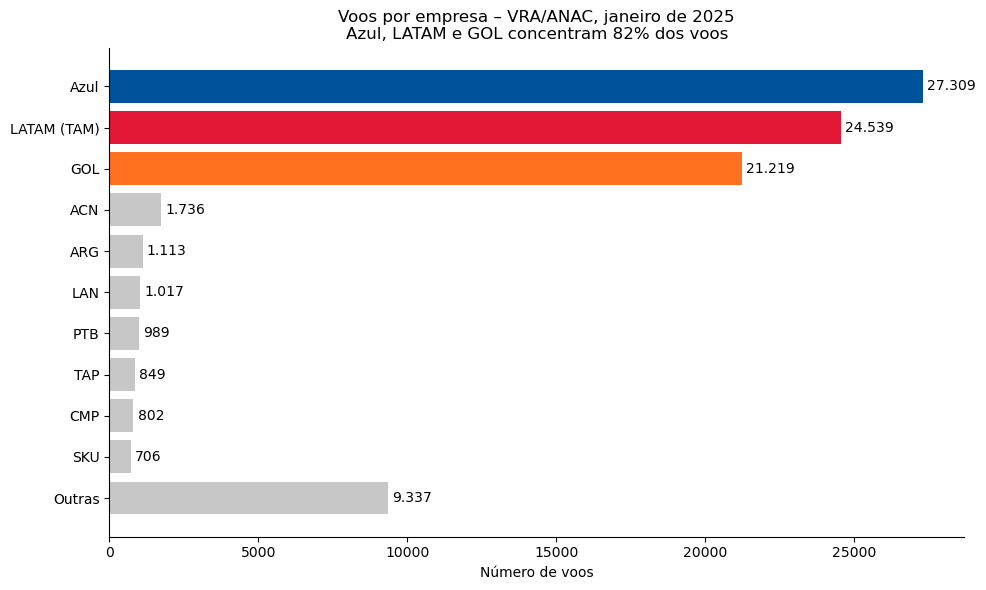

In [4]:
import matplotlib.pyplot as plt

# contagem de voos por empresa
contagem = df["Sigla ICAO Empresa Aérea"].value_counts()
print(f"Total de empresas na base: {len(contagem)}")

# participação das três maiores
tres = ["AZU", "TAM", "GLO"]
participacao = contagem[tres].sum() / contagem.sum() * 100
print(f"Azul, LATAM e GOL: {contagem[tres].sum():,} de {contagem.sum():,} voos ({participacao:.1f}%)")

# top 10 empresas + o restante agrupado em "Outras"
top = contagem.head(10).copy()
top["Outras"] = contagem.iloc[10:].sum()

# nomes legíveis para as três principais
nomes = {"AZU": "Azul", "TAM": "LATAM (TAM)", "GLO": "GOL"}
rotulos = [nomes.get(sigla, sigla) for sigla in top.index]
cores_empresas = {
    "AZU": "#00529B",  # azul
    "GLO": "#FF7020",  # laranja
    "TAM": "#E31837"   # vermelho
}

cores = [cores_empresas.get(sigla, "#c7c7c7") for sigla in top.index]

fig, ax = plt.subplots(figsize=(10, 6))
barras = ax.barh(rotulos[::-1], top.values[::-1], color=cores[::-1])
ax.bar_label(barras, labels=[f"{v:,}".replace(",", ".") for v in top.values[::-1]], padding=3)
ax.set_xlabel("Número de voos")
ax.set_title(f"Voos por empresa – VRA/ANAC, janeiro de 2025\n"
             f"Azul, LATAM e GOL concentram {participacao:.0f}% dos voos")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

A base contém registros de 76 companhias aéreas. Azul, LATAM e GOL concentram 73.067 registros, correspondentes a aproximadamente 81,5% do total. Essa participação justifica o recorte adotado para o estudo. O gráfico apresenta as dez companhias com mais registros e reúne as demais na categoria “Outras”.

### 2.2. Criação do df3

Foi criado o dataframe `df3`, contendo exclusivamente os registros de Azul (AZU), GOL (GLO) e LATAM (TAM). Esse recorte mantém as três companhias de interesse e preserva a base original para eventuais consultas.

In [5]:
pd.set_option("display.max_columns", None)  # mostra todas as colunas nas tabelas

# filtrar as três companhias
companhias = ["AZU", "TAM", "GLO"]
df3 = df[df["Sigla ICAO Empresa Aérea"].isin(companhias)].copy()
print(df3.shape)

(73067, 21)


### 2.3. Criação das variáveis de atraso
Foram criadas duas variáveis para avaliar a pontualidade na chegada. A variável `atraso_chegada` corresponde à diferença, em minutos, entre a chegada real e a prevista: valores positivos indicam atraso e valores negativos indicam antecipação. A variável `atrasou_15` assume valor 1 quando o atraso supera 15 minutos e 0 nos demais casos com informação disponível. Quando não é possível calcular o atraso, o valor permanece ausente. O limite de 15 minutos foi adotado como critério operacional deste estudo.

In [6]:
# atraso de chegada em minutos (positivo = atrasou, negativo = chegou antes)
df3["atraso_chegada"] = (df3["Chegada Real"] - df3["Chegada Prevista"]).dt.total_seconds() / 60

# versão binária: 1 = atrasou mais de 15 min, 0 = não atrasou
# voos sem atraso calculável ficam vazios (NA), e não como "não atrasou"
df3["atrasou_15"] = (df3["atraso_chegada"] > 15).astype("Int64").mask(df3["atraso_chegada"].isna())

# checagens
print(df3["atraso_chegada"].describe())
print(df3["atrasou_15"].value_counts(dropna=False))

count    70377.000000
mean         1.446026
std         43.683182
min        -79.000000
25%        -13.000000
50%         -5.000000
75%          6.000000
max       2866.000000
Name: atraso_chegada, dtype: float64
atrasou_15
0       60161
1       10216
<NA>     2690
Name: count, dtype: Int64


### 2.4. Seleção dos voos

In [7]:
df_atrasos = df3.loc[
    (df3["Situação Voo"] == "REALIZADO") &
    (df3["atraso_chegada"].notna())
].copy()

O dataframe `df_atrasos` reúne os voos realizados com informação suficiente para calcular o atraso na chegada, totalizando 70.377 registros. Dos 73.067 registros das três companhias, 2.690 não possuem atraso calculável, incluindo 1.534 cancelamentos. Esses registros ficam fora das comparações de atraso, pois a ausência de informação não pode ser interpretada como pontualidade. Os valores extremos de atraso foram mantidos, já que sua magnitude, isoladamente, não comprova erro no registro.

---
## 3. Análise dos atrasos

### 3.1. Analisando por companhia
Primeira análise de quantidade de voos, média e mediana do atraso e percentual com atraso superior a 15 minutos.

In [8]:
resumo = df_atrasos.groupby("Sigla ICAO Empresa Aérea").agg(
    quantidade_voos=("atraso_chegada", "size"),
    atraso_medio=("atraso_chegada", "mean"),
    atraso_mediano=("atraso_chegada", "median"),
    percentual_atrasados=("atrasou_15", "mean")
)

resumo["percentual_atrasados"] *= 100

resumo.round(2)

,quantidade_voos,atraso_medio,atraso_mediano,percentual_atrasados
Sigla ICAO Empresa Aérea,,,,
AZU,25774,4.87,-2.0,18.57
GLO,20844,-1.22,-8.0,9.98
TAM,23759,0.08,-4.0,14.1


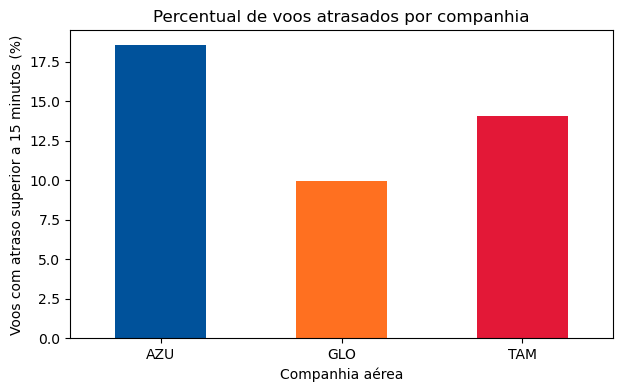

In [9]:
resumo["percentual_atrasados"].plot(
    kind="bar",
    figsize=(7, 4),
    rot=0, color=["#00529B", "#FF7020", "#E31837"])

plt.xlabel("Companhia aérea")
plt.ylabel("Voos com atraso superior a 15 minutos (%)")
plt.title("Percentual de voos atrasados por companhia")
plt.show()

Entre os voos analisados, a Azul apresentou o maior percentual de chegadas com atraso superior a 15 minutos (18,57%), seguida pela LATAM (14,10%) e pela GOL (9,98%). A diferença entre Azul e GOL foi de 8,59 pontos percentuais.

As medianas foram negativas nas três companhias, indicando que pelo menos metade dos voos chegou antes do horário previsto. Entretanto, os atrasos, especialmente os mais elevados, aumentam a média. Por isso, a média próxima de zero da LATAM não significa ausência de atrasos: 14,10% de seus voos ultrapassaram o limite adotado.

Esses resultados descrevem diferenças gerais entre as companhias, mas ainda não consideram os aeroportos, horários e rotas em que cada uma opera.

### 3.2. Analisando por horário
Nesta seção, analisa-se o percentual de voos com atraso na chegada superior a 15 minutos conforme a hora prevista da partida, considerando conjuntamente as três companhias.

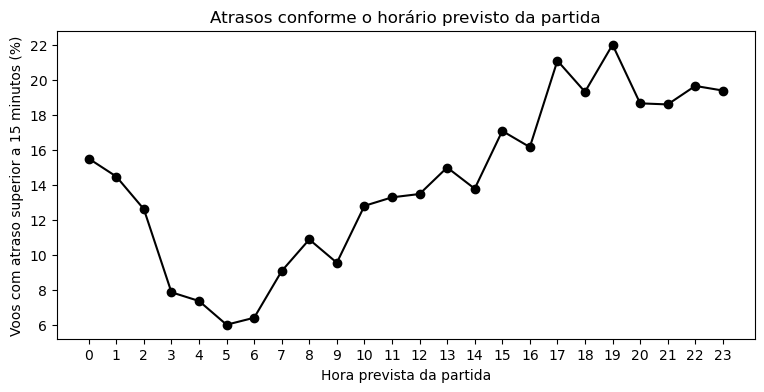

In [10]:
df_atrasos["hora_partida"] = df_atrasos["Partida Prevista"].dt.hour

atraso_horario = df_atrasos.groupby(
    "hora_partida"
)["atrasou_15"].mean() * 100

atraso_horario.plot(figsize=(9, 4), marker="o", color='black')

plt.xlabel("Hora prevista da partida")
plt.ylabel("Voos com atraso superior a 15 minutos (%)")
plt.title("Atrasos conforme o horário previsto da partida")
plt.xticks(range(24))
plt.show()

O percentual de atrasos na chegada varia conforme a hora prevista da partida. Entre os voos previstos para as 5h e 6h, os percentuais foram de aproximadamente 6,01% e 6,41%, enquanto às 17h e 19h atingiram 21,08% e 21,99%.

Observa-se uma tendência de percentuais maiores no fim da tarde e à noite, embora o crescimento não seja contínuo. O acúmulo de atrasos ao longo do dia é uma possível explicação, mas essa hipótese não pode ser comprovada apenas com os resultados apresentados.

### 3.3. Comparar os horários para cada companhia

Para aprofundar a análise, o percentual de atrasos por hora prevista de partida foi calculado separadamente para cada companhia. Essa comparação permite verificar se o comportamento observado no conjunto também aparece em cada empresa e se a ordem entre as companhias varia ao longo do dia. Ainda assim, voos no mesmo horário podem ter diferentes origens, destinos e datas.

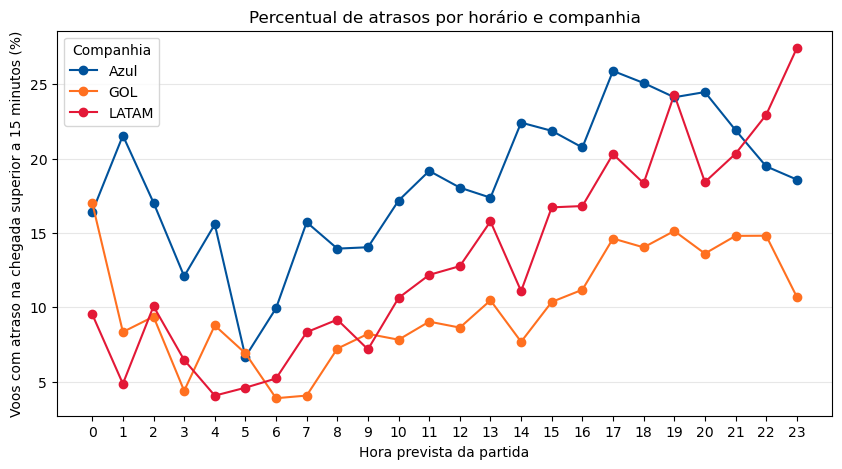

In [11]:
atraso_hora_empresa = df_atrasos.groupby(
    ["hora_partida", "Sigla ICAO Empresa Aérea"]
)["atrasou_15"].mean().unstack() * 100

atraso_hora_empresa = atraso_hora_empresa.rename(
    columns={"AZU": "Azul", "GLO": "GOL", "TAM": "LATAM"}
)

atraso_hora_empresa.plot(figsize=(10, 5), marker="o", color=["#00529B", "#FF7020", "#E31837"])

plt.xlabel("Hora prevista da partida")
plt.ylabel("Voos com atraso na chegada superior a 15 minutos (%)")
plt.title("Percentual de atrasos por horário e companhia")
plt.xticks(range(24))
plt.legend(title="Companhia")
plt.grid(axis="y", alpha=0.3)
plt.show()

Ao separar os resultados por companhia, observa-se que a Azul apresenta o maior percentual de atrasos na maioria dos horários previstos de partida. A GOL, por sua vez, apresenta os menores percentuais entre as 10h e as 23h.

As três companhias apresentam percentuais mais elevados no fim da tarde e à noite do que no início da manhã. Às 5h, os resultados ficam próximos, variando de 4,59% a 6,90%. Às 17h, as diferenças são maiores: a Azul apresenta 25,90%, a LATAM 20,30% e a GOL 14,62%.

A posição das empresas também muda ao longo do dia. Às 19h, Azul e LATAM apresentam percentuais semelhantes, próximos de 24%. Às 22h e 23h, a LATAM supera a Azul, chegando a 27,42% às 23h.

Esses resultados mostram que a diferença entre as companhias varia conforme o horário. Entretanto, a comparação ainda reúne voos de diferentes aeroportos, rotas e datas, o que motiva a análise seguinte, com origem e período semelhantes.

---
## 4. Comparação em condições semelhantes

### 4.1. Seleção de aeroportos com presença das três companhias

Foram selecionados aeroportos de origem com pelo menos 100 voos analisáveis de cada uma das três companhias no mês. Esse critério busca evitar comparações baseadas em poucos registros por empresa no aeroporto. Entretanto, ao dividir os voos por período do dia, alguns grupos ainda podem apresentar quantidades reduzidas.

In [12]:
quantidade_aeroporto = pd.crosstab(
    df_atrasos["Sigla ICAO Aeroporto Origem"],
    df_atrasos["Sigla ICAO Empresa Aérea"]
)

# Selecionar aeroportos com pelo menos 100 voos de cada companhia
aeroportos_comuns = quantidade_aeroporto.loc[
    (quantidade_aeroporto >= 100).all(axis=1)
].copy()

aeroportos_comuns["Total"] = aeroportos_comuns.sum(axis=1)

aeroportos_comuns.sort_values("Total", ascending=False).head()

Sigla ICAO Empresa Aérea,AZU,GLO,TAM,Total
Sigla ICAO Aeroporto Origem,,,,
SBGR,831,2938,5755,9524
SBSP,942,3331,3418,7691
SBCF,3373,631,562,4566
SBBR,468,1651,2212,4331
SBRF,2423,567,495,3485


### 4.2. Escolha do aeroporto analisado

In [13]:
aeroporto = aeroportos_comuns["Total"].idxmax()

df_aeroporto = df_atrasos.loc[
    df_atrasos["Sigla ICAO Aeroporto Origem"] == aeroporto
].copy()

print("Aeroporto selecionado:", aeroporto)

Aeroporto selecionado: SBGR


Entre os aeroportos que atenderam ao critério, Guarulhos (SBGR) apresentou o maior número de voos analisáveis, com 9.524 registros. Por esse motivo, foi escolhido para a comparação entre companhias e períodos do dia. Esse recorte permite comparar voos com a mesma origem, embora outras características das operações ainda possam diferir.

### 4.3. Comparação por companhia e período do dia no aeroporto selecionado

Os voos com origem em Guarulhos foram agrupados conforme o período previsto de partida: madrugada (0h–5h), manhã (6h–11h), tarde (12h–17h) e noite (18h–23h). Para cada companhia e período, foram calculados a quantidade de voos analisados e o percentual de chegadas com atraso superior a 15 minutos.

In [16]:
df_aeroporto["periodo"] = pd.cut(
    df_aeroporto["hora_partida"],
    bins=[0, 6, 12, 18, 24],
    labels=["Madrugada", "Manhã", "Tarde", "Noite"],
    right=False
)

comparacao = df_aeroporto.groupby(
    ["periodo", "Sigla ICAO Empresa Aérea"],
    observed=True
).agg(
    quantidade_voos=("atrasou_15", "size"),
    percentual_atrasados=("atrasou_15", "mean")
)

comparacao["percentual_atrasados"] *= 100

comparacao.round(2)

quantidade_voos  percentual_atrasados
periodo   Sigla ICAO Empresa Aérea                                       
Madrugada AZU                                    58                  1.72
          GLO                                   214                  6.07
          TAM                                    92                  7.61
Manhã     AZU                                   286                 10.84
          GLO                                   947                 11.62
          TAM                                  1758                  11.6
Tarde     AZU                                   280                 20.71
          GLO                                   951                 11.78
          TAM                                  2087                 21.61
Noite     AZU                                   207                 14.49
          GLO                                   826                 17.92
          TAM                                  1818                 28.66

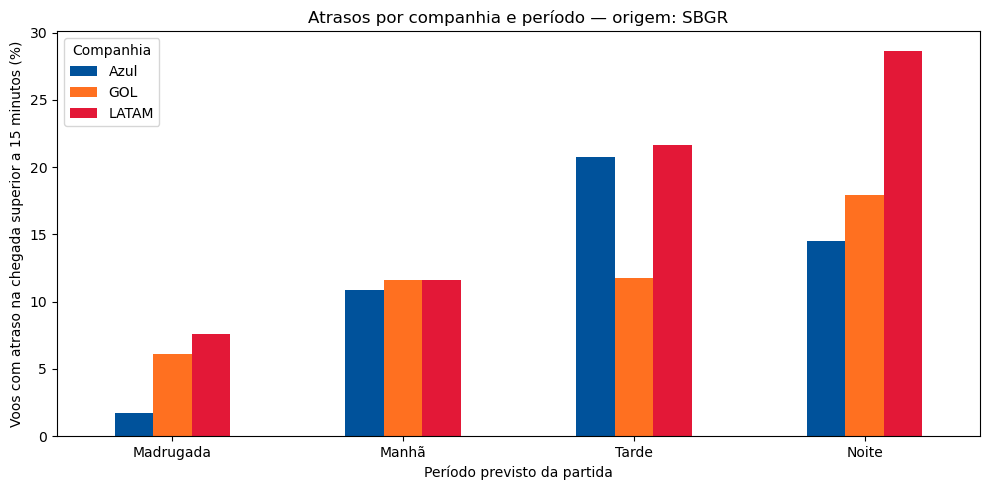

In [15]:
comparacao["percentual_atrasados"].unstack().rename(
    columns={"AZU": "Azul", "GLO": "GOL", "TAM": "LATAM"}
).plot(kind="bar", figsize=(10, 5), rot=0, color=["#00529B", "#FF7020", "#E31837"])

plt.xlabel("Período previsto da partida")
plt.ylabel("Voos com atraso na chegada superior a 15 minutos (%)")
plt.title(f"Atrasos por companhia e período — origem: {aeroporto}")
plt.legend(title="Companhia")
plt.tight_layout()
plt.show()

Em Guarulhos, a ordem observada na comparação geral não se mantém em todos os períodos. A Azul apresenta o menor percentual de atrasos na madrugada, manhã e noite, enquanto a GOL apresenta o menor percentual à tarde. Pela manhã, os resultados das três companhias são próximos, variando de 10,84% a 11,62%. À noite, a diferença é maior: a LATAM apresenta 28,66%, a GOL 17,92% e a Azul 14,49%.

Os resultados da madrugada exigem maior cautela, pois incluem apenas 58 voos da Azul e 92 da LATAM. Nesses grupos, poucos atrasos já modificam bastante os percentuais.

A comparação mostra que o resultado agregado não representa todas as condições de operação. Entretanto, considerar a mesma origem e o mesmo período ainda não elimina diferenças de destino, data e tipo de voo.

A análise identificou diferenças no percentual de atrasos superiores a 15 minutos entre companhias e horários previstos de partida. No conjunto dos voos analisados, a Azul apresentou o maior percentual e a GOL, o menor. Também foram observados percentuais maiores no fim da tarde e à noite.

Entretanto, a comparação em Guarulhos mostrou que a ordem entre as companhias varia conforme o período. Assim, o desempenho agregado deve ser interpretado considerando as características das operações, sem atribuir as diferenças exclusivamente à companhia aérea.

O estudo se limita a janeiro de 2025 e aos voos realizados com informação disponível de chegada. Cancelamentos não foram avaliados como atrasos, e a comparação detalhada por período abrangeu apenas Guarulhos. Além disso, não foram consideradas conjuntamente características como rota, data, tipo de voo e condições meteorológicas. Portanto, os resultados descrevem associações e não permitem estabelecer causas ou generalizar o comportamento para o ano inteiro.